In [1]:
import pandas as pd
import numpy as np
import random
import time
import pickle
import os
import sys

sys.path.append(os.path.abspath('..'))

from sklearn.model_selection import StratifiedKFold
from IPython.display import display

from utils.graphs import plot_confusion_matrix
from utils.util import evaluate_predictions, cross_evaluate_adversarial_learning
from utils.models import available_models, get_model


print("Pandas version: {}".format(pd.__version__))
print("NumPy version: {}".format(np.__version__))

seed = 42
np.random.seed(seed)
random.seed(seed)

Pandas version: 2.2.2
NumPy version: 2.0.1


# Load the data

In [2]:
df = pd.read_parquet("../../data/CSECICIDS2018_improved/clean/wednesday-latest.parquet")

adv_files = [
    "patator-ssh-cic.parquet",
    "patator-versions-ssh-cic.parquet",
    "patator-network-ssh-cic.parquet",
    "hydra-ssh-cic.parquet",
    "medusa-ssh-cic.parquet",
]
df_adv = pd.concat([pd.read_parquet(f"../../data/concap/clean/{f}") for f in adv_files], ignore_index=True)
df_adv.scenario.value_counts()

scenario
patator_ssh_cic_T5                     3400
patator_ssh_cic_T10                    3400
patator_ssh_cic_T1                     3400
medusa_ssh_cic_ubuntu24_T10_default    1151
medusa_ssh_cic_ubuntu24_T10_long       1151
medusa_ssh_cic_ubuntu20_T10_long       1149
medusa_ssh_cic_ubuntu18_T10_long       1149
medusa_ssh_cic_ubuntu20_T10_min        1148
medusa_ssh_cic_ubuntu20_T10_default    1148
medusa_ssh_cic_ubuntu18_T10_default    1147
medusa_ssh_cic_ubuntu18_T10_min        1147
medusa_ssh_cic_ubuntu24_T10_min        1145
hydra_ssh_cic_ubuntu20_T10              758
hydra_ssh_cic_ubuntu24_T10              755
hydra_ssh_cic_ubuntu18_T10              727
patator_ssh_cic_D10_L0_C0_Dup0          680
patator_ssh_cic_D25_L5_C5_Dup5          680
patator_ssh_cic_D100_L0_C5_Dup5         680
patator_ssh_cic_D10_L5_C0_Dup5          680
patator_ssh_cic_D10_L5_C0_Dup0          680
patator_ssh_cic_D25_L0_C5_Dup0          680
patator_ssh_cic_D100_L5_C0_Dup0         680
patator_ssh_cic_D100_L5

# Prepare for evaluation

In [3]:
result_dir = "../results/csecicids2018-latest/defense"
if not os.path.exists(result_dir):
    os.makedirs(result_dir)

In [4]:
train_scenarios = [ # train on scenarios with single and 10 threads, test on 5 threads.
    'patator-ssh-cic-t1',
    'patator-ssh-cic-t10',
    # 'patator-ssh-cic-t5',
    'patator-ssh-cic-t10-p-rl1',
    'patator-ssh-cic-t10-p',
    # 'patator-ssh-cic-t5-p',
    # 'patator-ssh-cic-t5-p-rl1',
    'patator-ssh-cic-t1-p',
    'patator-ssh-cic-t1-p-rl1'
]
df_adv['scenario'] = df_adv.scenario.map(lambda x: x.replace("_", "-").lower())
X_adv, y_adv, groups = df_adv.drop(columns=["Label", "scenario"]), pd.Series(np.ones(df_adv.shape[0])), df_adv["scenario"]
X_adv_train, y_adv_train, groups_train = X_adv[df_adv.scenario.isin(train_scenarios)], y_adv[df_adv.scenario.isin(train_scenarios)], groups[df_adv.scenario.isin(train_scenarios)]
X_adv_test, y_adv_test, groups_test = X_adv[~df_adv.scenario.isin(train_scenarios)], y_adv[~df_adv.scenario.isin(train_scenarios)], groups[~df_adv.scenario.isin(train_scenarios)]

In [5]:
groups_train.value_counts()

scenario
patator-ssh-cic-t10          3400
patator-ssh-cic-t1           3400
patator-ssh-cic-t10-p-rl1     680
patator-ssh-cic-t10-p         680
patator-ssh-cic-t1-p          578
patator-ssh-cic-t1-p-rl1      578
Name: count, dtype: int64

In [6]:
X, y = df.drop(columns=["Label"]), df["Label"].map(lambda x: 0 if x == "BENIGN" else 1)
del df

# Adversarial training as Defense

We evaluate adversarial learning as potential defense against the true-problem space attacks. The adversarial perturbations are split into training and test set. The training set is added to training in each loop of the cross-validation. The test set is used to evaluate if the defense is successful.

Evaluating model: decision_tree


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,40.407612,1.437475,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370087, 0], [0, 84673]]",0.339684,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,45.562167,1.262332,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",0.311053,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,34.686329,1.303337,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",0.391129,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,35.692963,1.439337,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",0.361106,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,40.746581,1.368191,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370088, 0], [0, 84673]]",0.342575,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842521, 1: 18840}",861361.000000,"[[842520, 1], [0, 18840]]"
mean,39.419130,1.362134,1.0,1.0,1.0,1.0,1.0,NaN,3.454761e+06,NaN,0.349109,0.999995,1.0,0.999989,9.999998e-01,9.999998e-01,NaN,861361.200000,NaN
std,4.380635,0.079200,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.029536,0.000012,0.0,0.000024,5.191942e-07,5.308041e-07,NaN,0.447214,NaN


Aggregated test confusion matrix:


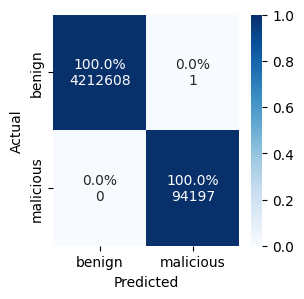

Training time for on all data: 40.8139

Evaluating model: decision_tree_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,41.451334,5.032065,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370087, 0], [0, 84673]]",0.588209,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,41.826372,3.952879,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",0.563756,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,51.085061,2.138172,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",0.467014,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,50.803753,2.264715,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",0.516141,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,41.388615,3.389061,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370088, 0], [0, 84673]]",0.546534,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,45.311027,3.355379,1.0,1.0,1.0,1.0,1.0,NaN,3.454761e+06,NaN,0.536331,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,5.146233,1.208362,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.046797,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


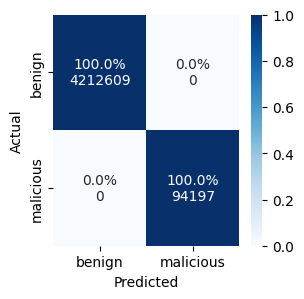

Training time for on all data: 45.6717

Evaluating model: logistic_regression


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,33.090853,3.308921,0.998332,1.0,0.996669,0.999918,0.999916,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3369804, 283], [0, 84673]]",0.595321,0.997881,1.0,0.995772,0.999907,0.999905,"{0: 842522, 1: 18840}",861362.000000,"[[842442, 80], [0, 18840]]"
1,30.263614,4.256872,0.998496,1.0,0.996997,0.999926,0.999924,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3369832, 255], [0, 84674]]",0.817746,0.998304,1.0,0.996614,0.999926,0.999924,"{0: 842522, 1: 18839}",861361.000000,"[[842458, 64], [0, 18839]]"
2,34.190367,3.642233,0.998508,1.0,0.997021,0.999927,0.999925,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3369834, 253], [0, 84674]]",0.548801,0.998331,1.0,0.996667,0.999927,0.999925,"{0: 842522, 1: 18839}",861361.000000,"[[842459, 63], [0, 18839]]"
3,23.252039,4.135180,0.998508,1.0,0.997021,0.999927,0.999925,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3369834, 253], [0, 84674]]",0.856737,0.998569,1.0,0.997142,0.999937,0.999936,"{0: 842522, 1: 18839}",861361.000000,"[[842468, 54], [0, 18839]]"
4,26.107669,4.534834,0.998561,1.0,0.997127,0.999929,0.999928,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3369844, 244], [0, 84673]]",0.704685,0.998516,1.0,0.997036,0.999935,0.999934,"{0: 842521, 1: 18840}",861361.000000,"[[842465, 56], [0, 18840]]"
mean,29.380908,3.975608,0.998481,1.0,0.996967,0.999925,0.999924,NaN,3.454761e+06,NaN,0.704658,0.998320,1.0,0.996646,0.999926,0.999925,NaN,861361.200000,NaN
std,4.635485,0.493183,0.000087,0.0,0.000174,0.000004,0.000004,NaN,4.472136e-01,NaN,0.134316,0.000271,0.0,0.000539,0.000012,0.000012,NaN,0.447214,NaN


Aggregated test confusion matrix:


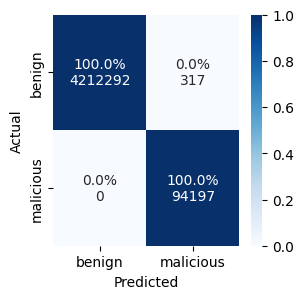

Training time for on all data: 17.0998

Evaluating model: logistic_regression_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,31.469797,4.068966,0.998332,1.0,0.996669,0.999918,0.999916,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3369804, 283], [0, 84673]]",1.095765,0.997881,1.0,0.995772,0.999907,0.999905,"{0: 842522, 1: 18840}",861362.000000,"[[842442, 80], [0, 18840]]"
1,36.201223,3.878311,0.998496,1.0,0.996997,0.999926,0.999924,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3369832, 255], [0, 84674]]",0.862581,0.998304,1.0,0.996614,0.999926,0.999924,"{0: 842522, 1: 18839}",861361.000000,"[[842458, 64], [0, 18839]]"
2,34.714692,4.010489,0.998508,1.0,0.997021,0.999927,0.999925,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3369834, 253], [0, 84674]]",0.886718,0.998331,1.0,0.996667,0.999927,0.999925,"{0: 842522, 1: 18839}",861361.000000,"[[842459, 63], [0, 18839]]"
3,38.051261,4.548040,0.998508,1.0,0.997021,0.999927,0.999925,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3369834, 253], [0, 84674]]",0.722131,0.998569,1.0,0.997142,0.999937,0.999936,"{0: 842522, 1: 18839}",861361.000000,"[[842468, 54], [0, 18839]]"
4,31.110006,5.842227,0.998561,1.0,0.997127,0.999929,0.999928,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3369844, 244], [0, 84673]]",0.779558,0.998516,1.0,0.997036,0.999935,0.999934,"{0: 842521, 1: 18840}",861361.000000,"[[842465, 56], [0, 18840]]"
mean,34.309396,4.469606,0.998481,1.0,0.996967,0.999925,0.999924,NaN,3.454761e+06,NaN,0.869351,0.998320,1.0,0.996646,0.999926,0.999925,NaN,861361.200000,NaN
std,3.001843,0.807956,0.000087,0.0,0.000174,0.000004,0.000004,NaN,4.472136e-01,NaN,0.142607,0.000271,0.0,0.000539,0.000012,0.000012,NaN,0.447214,NaN


Aggregated test confusion matrix:


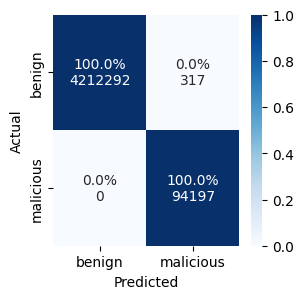

Training time for on all data: 21.0838

Evaluating model: one_rule


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,302.867690,0.952394,0.832175,1.0,0.712586,0.990115,0.989866,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3335935, 34152], [0, 84673]]",0.257401,0.814949,1.0,0.687692,0.990067,0.989845,"{0: 842522, 1: 18840}",861362.000000,"[[833966, 8556], [0, 18840]]"
1,356.496179,0.863605,0.832034,1.0,0.712378,0.990104,0.989856,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3335900, 34187], [0, 84674]]",0.262558,0.815559,1.0,0.688560,0.990108,0.989886,"{0: 842522, 1: 18839}",861361.000000,"[[834001, 8521], [0, 18839]]"
2,357.519633,0.987795,0.831776,1.0,0.712001,0.990086,0.989837,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3335837, 34250], [0, 84674]]",0.227002,0.816672,1.0,0.690149,0.990181,0.989961,"{0: 842522, 1: 18839}",861361.000000,"[[834064, 8458], [0, 18839]]"
3,304.575846,0.959091,0.832165,1.0,0.712570,0.990114,0.989865,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3335932, 34155], [0, 84674]]",0.279059,0.814994,1.0,0.687756,0.990070,0.989848,"{0: 842522, 1: 18839}",861361.000000,"[[833969, 8553], [0, 18839]]"
4,410.990641,0.863668,0.832437,1.0,0.712970,0.990133,0.989885,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3336000, 34088], [0, 84673]]",0.215362,0.813823,1.0,0.686089,0.989993,0.989769,"{0: 842521, 1: 18840}",861361.000000,"[[833901, 8620], [0, 18840]]"
mean,346.489998,0.925311,0.832117,1.0,0.712501,0.990110,0.989862,NaN,3.454761e+06,NaN,0.248276,0.815200,1.0,0.688049,0.990084,0.989862,NaN,861361.200000,NaN
std,44.838074,0.057850,0.000240,0.0,0.000352,0.000017,0.000017,NaN,4.472136e-01,NaN,0.026319,0.001037,0.0,0.001477,0.000068,0.000070,NaN,0.447214,NaN


Aggregated test confusion matrix:


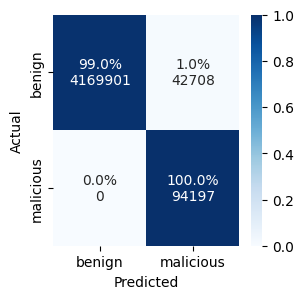

Training time for on all data: 3.8057

Evaluating model: one_rule_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,299.006650,1.806458,0.832175,1.0,0.712586,0.990115,0.989866,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3335935, 34152], [0, 84673]]",0.484198,0.814949,1.0,0.687692,0.990067,0.989845,"{0: 842522, 1: 18840}",861362.000000,"[[833966, 8556], [0, 18840]]"
1,389.663542,1.522201,0.832034,1.0,0.712378,0.990104,0.989856,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3335900, 34187], [0, 84674]]",0.388983,0.815559,1.0,0.688560,0.990108,0.989886,"{0: 842522, 1: 18839}",861361.000000,"[[834001, 8521], [0, 18839]]"
2,302.618551,1.825119,0.831776,1.0,0.712001,0.990086,0.989837,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3335837, 34250], [0, 84674]]",0.463934,0.816672,1.0,0.690149,0.990181,0.989961,"{0: 842522, 1: 18839}",861361.000000,"[[834064, 8458], [0, 18839]]"
3,358.108935,1.552132,0.832165,1.0,0.712570,0.990114,0.989865,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3335932, 34155], [0, 84674]]",0.388262,0.814994,1.0,0.687756,0.990070,0.989848,"{0: 842522, 1: 18839}",861361.000000,"[[833969, 8553], [0, 18839]]"
4,332.463640,1.641175,0.832437,1.0,0.712970,0.990133,0.989885,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3336000, 34088], [0, 84673]]",0.426581,0.813823,1.0,0.686089,0.989993,0.989769,"{0: 842521, 1: 18840}",861361.000000,"[[833901, 8620], [0, 18840]]"
mean,336.372264,1.669417,0.832117,1.0,0.712501,0.990110,0.989862,NaN,3.454761e+06,NaN,0.430392,0.815200,1.0,0.688049,0.990084,0.989862,NaN,861361.200000,NaN
std,38.285842,0.140756,0.000240,0.0,0.000352,0.000017,0.000017,NaN,4.472136e-01,NaN,0.043372,0.001037,0.0,0.001477,0.000068,0.000070,NaN,0.447214,NaN


Aggregated test confusion matrix:


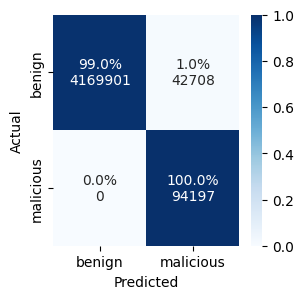

Best feature index: 73
Best feature index: 70


Best feature index: 73
Best feature index: 70


Best feature index: 73
Best feature index: 70


Best feature index: 73
Best feature index: 70


Best feature index: 73
Best feature index: 70


Best feature index: 70
Training time for on all data: 350.1154

Evaluating model: random_forest


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,735.610423,6.124666,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370087, 0], [0, 84673]]",1.315931,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,671.483961,6.470635,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",1.390151,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,686.223066,6.243589,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",1.361108,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,620.608128,6.698341,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",1.472675,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,629.563408,9.244003,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370088, 0], [0, 84673]]",1.982339,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,668.697797,6.956247,1.0,1.0,1.0,1.0,1.0,NaN,3.454761e+06,NaN,1.504441,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,46.465885,1.297649,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.273193,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


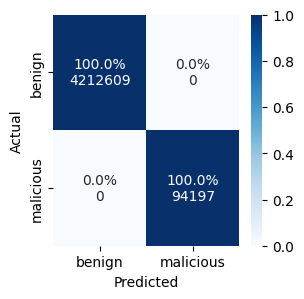

Training time for on all data: 759.7665

Evaluating model: random_forest_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,825.537971,7.046128,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370087, 0], [0, 84673]]",1.557573,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,711.269591,7.797130,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",1.633926,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,700.390043,7.625466,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",1.786803,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
3,809.648516,7.120805,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",1.525711,1.0,1.0,1.0,1.0,1.0,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
4,703.399758,7.691521,1.0,1.0,1.0,1.0,1.0,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370088, 0], [0, 84673]]",1.666948,1.0,1.0,1.0,1.0,1.0,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,750.049176,7.456210,1.0,1.0,1.0,1.0,1.0,NaN,3.454761e+06,NaN,1.634192,1.0,1.0,1.0,1.0,1.0,NaN,861361.200000,NaN
std,62.041706,0.346738,0.0,0.0,0.0,0.0,0.0,NaN,4.472136e-01,NaN,0.102472,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


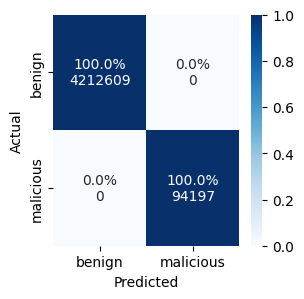

Training time for on all data: 836.8174

Evaluating model: neural_network


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,394.975098,39.701125,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370087, 0], [0, 84673]]",10.751275,1.000000,1.0,1.000000,1.000000,1.000000,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,379.734493,43.375295,0.999988,1.0,0.999976,0.999999,0.999999,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",10.773038,1.000000,1.0,1.000000,1.000000,1.000000,"{0: 842522, 1: 18839}",861361.000000,"[[842522, 0], [0, 18839]]"
2,385.698228,37.394482,0.999988,1.0,0.999976,0.999999,0.999999,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.232796,0.999973,1.0,0.999947,0.999999,0.999999,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
3,406.409773,52.066774,1.000000,1.0,1.000000,1.000000,1.000000,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",11.824582,0.999973,1.0,0.999947,0.999999,0.999999,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
4,445.034066,41.596924,0.999900,1.0,0.999799,0.999995,0.999995,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370071, 17], [0, 84673]]",10.253348,0.999920,1.0,0.999841,0.999997,0.999996,"{0: 842521, 1: 18840}",861361.000000,"[[842518, 3], [0, 18840]]"
mean,402.370331,42.826920,0.999975,1.0,0.999950,0.999999,0.999999,NaN,3.454761e+06,NaN,10.567008,0.999973,1.0,0.999947,0.999999,0.999999,NaN,861361.200000,NaN
std,25.891799,5.622955,0.000043,0.0,0.000085,0.000002,0.000002,NaN,4.472136e-01,NaN,0.940266,0.000033,0.0,0.000065,0.000001,0.000001,NaN,0.447214,NaN


Aggregated test confusion matrix:


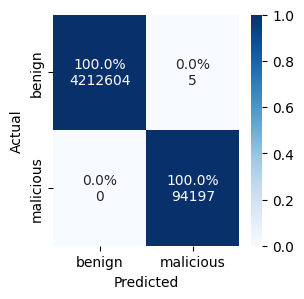

Training time for on all data: 398.9085

Evaluating model: neural_network_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,406.080064,47.572025,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370087, 0], [0, 84673]]",9.187302,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,396.741181,38.629607,0.999988,1.0,0.999976,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.673908,0.999947,1.0,0.999894,9.999977e-01,9.999976e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842520, 2], [0, 18839]]"
2,423.338727,56.050445,0.999988,1.0,0.999976,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",13.863451,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
3,432.035217,38.733800,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370087, 0], [0, 84674]]",10.188423,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
4,463.855393,49.846134,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370088, 0], [0, 84673]]",11.484016,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,424.410116,46.166402,0.999995,1.0,0.999991,9.999998e-01,9.999998e-01,NaN,3.454761e+06,NaN,10.879420,0.999979,1.0,0.999958,9.999991e-01,9.999991e-01,NaN,861361.200000,NaN
std,26.061373,7.504288,0.000006,0.0,0.000013,3.170827e-07,3.250495e-07,NaN,4.472136e-01,NaN,1.875098,0.000022,0.0,0.000044,9.713233e-07,9.930423e-07,NaN,0.447214,NaN


Aggregated test confusion matrix:


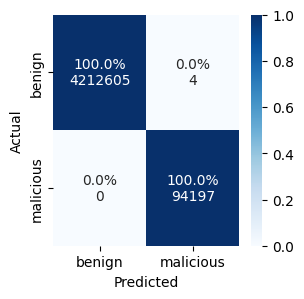

Training time for on all data: 408.3986

Evaluating model: support_vector_machine


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,155.900965,35.249557,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370085, 2], [0, 84673]]",8.554793,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,127.502922,39.972883,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.105048,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
2,96.155820,37.953705,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.510270,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
3,90.412664,38.116606,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.389413,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
4,83.042047,37.150168,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370086, 2], [0, 84673]]",8.816404,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,110.602884,37.688584,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,NaN,3.454761e+06,NaN,9.075186,0.999984,1.0,0.999968,9.999993e-01,9.999993e-01,NaN,861361.200000,NaN
std,30.469205,1.711013,7.639329e-11,0.0,1.527830e-10,7.497253e-14,7.874605e-14,NaN,4.472136e-01,NaN,0.395823,0.000015,0.0,0.000029,6.358804e-07,6.500988e-07,NaN,0.447214,NaN


Aggregated test confusion matrix:


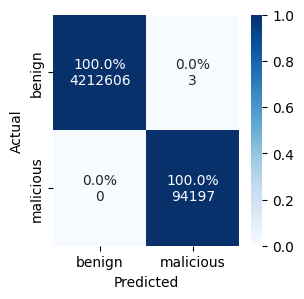

Training time for on all data: 119.8236

Evaluating model: support_vector_machine_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,158.999823,33.839260,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84673}",3.454760e+06,"[[3370085, 2], [0, 84673]]",8.451388,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842522, 1: 18840}",861362.000000,"[[842522, 0], [0, 18840]]"
1,87.707663,38.539840,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.510158,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
2,96.782892,37.330826,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.135732,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
3,92.431332,36.699108,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370087, 1.0: 84674}",3.454761e+06,"[[3370085, 2], [0, 84674]]",9.214820,0.999973,1.0,0.999947,9.999988e-01,9.999988e-01,"{0: 842522, 1: 18839}",861361.000000,"[[842521, 1], [0, 18839]]"
4,127.993552,39.305453,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,"{0.0: 3370088, 1.0: 84673}",3.454761e+06,"[[3370086, 2], [0, 84673]]",7.897058,1.000000,1.0,1.000000,1.000000e+00,1.000000e+00,"{0: 842521, 1: 18840}",861361.000000,"[[842521, 0], [0, 18840]]"
mean,112.783052,37.142898,9.999882e-01,1.0,9.999764e-01,9.999994e-01,9.999994e-01,NaN,3.454761e+06,NaN,8.841831,0.999984,1.0,0.999968,9.999993e-01,9.999993e-01,NaN,861361.200000,NaN
std,30.275080,2.107984,7.639329e-11,0.0,1.527830e-10,7.497253e-14,7.874605e-14,NaN,4.472136e-01,NaN,0.655210,0.000015,0.0,0.000029,6.358804e-07,6.500988e-07,NaN,0.447214,NaN


Aggregated test confusion matrix:


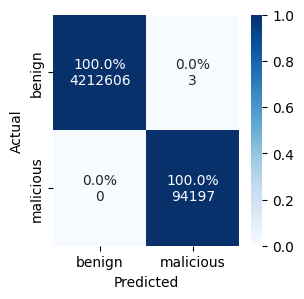

Training time for on all data: 120.8027



In [7]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in available_models:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate_adversarial_learning(ml_pipeline, X, y, X_adv_train, y_adv_train, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    if model_name == 'one_rule':
        # Prevent information leakage by using the best rule from the cross evaluation
        models[model_name] = ml_pipeline.fit(pd.concat([X, X_adv_train]), pd.concat([y, y_adv_train]), clf__feature_idx=8)
    else:
        models[model_name] = ml_pipeline.fit(pd.concat([X, X_adv_train]), pd.concat([y, y_adv_train]))
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()

# Adversarial Evaluation

In [8]:
baseline_dir = result_dir

In [9]:
for model_name in available_models:
    print("Evaluating model: {}".format(model_name))
    with open(f"{baseline_dir}/{model_name}.p", "rb") as f:
        ml_pipeline = pickle.load(f)
        recall_before_attack = pd.read_csv(f"{baseline_dir}/{model_name}_results.csv", index_col=0).loc['mean', 'test_recall']
        results = []
        
        for scenario in groups_train.unique():
            X_scenario, y_scenario = X_adv_train[groups_train == scenario], y_adv_train[groups_train == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            
            recall_after_attack = np.sum(y_pred == 1) / y_scenario.shape[0]
            result = {
                'status': 'train',
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1),
                'recall_before_attack': recall_before_attack,
                'recall_after_attack': recall_after_attack,
                'attack_severity': 1 - (recall_after_attack / recall_before_attack)
            }
            results.append(result)
        for scenario in groups_test.unique():
            X_scenario, y_scenario = X_adv_test[groups_test == scenario], y_adv_test[groups_test == scenario]
            start_time = time.time()
            y_pred = ml_pipeline.predict(X_scenario)
            end_time = time.time() - start_time
            
            recall_after_attack = np.sum(y_pred == 1) / y_scenario.shape[0]
            result = {
                'status': 'test',
                'scenario': scenario,
                'pred_time': end_time,
                'pred_benign': np.sum(y_pred == 0),
                'pred_attack': np.sum(y_pred == 1),
                'recall_before_attack': recall_before_attack,
                'recall_after_attack': recall_after_attack,
                'attack_severity': 1 - (recall_after_attack / recall_before_attack)
            }
            results.append(result)
        results = pd.DataFrame(results)
        display(results)
        results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)

Evaluating model: decision_tree


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.001944,0,578,1.0,1.000000,0.000000
1,train,patator-ssh-cic-t10,0.001997,0,3400,1.0,1.000000,0.000000
2,train,patator-ssh-cic-t1-p-rl1,0.001459,0,578,1.0,1.000000,0.000000
3,train,patator-ssh-cic-t1,0.001899,0,3400,1.0,1.000000,0.000000
4,train,patator-ssh-cic-t10-p,0.001360,0,680,1.0,1.000000,0.000000
5,train,patator-ssh-cic-t10-p-rl1,0.001472,0,680,1.0,1.000000,0.000000
6,test,patator-ssh-cic-t5,0.002058,0,3400,1.0,1.000000,0.000000
7,test,patator-ssh-cic-t5-p-rl1,0.001688,0,595,1.0,1.000000,0.000000
8,test,patator-ssh-cic-t5-p,0.001637,0,595,1.0,1.000000,0.000000
9,test,patator-ssh-cic-ubuntu22,0.001453,680,0,1.0,0.000000,1.000000


Evaluating model: decision_tree_vt


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.001755,0,578,1.0,1.000000,0.000000
1,train,patator-ssh-cic-t10,0.002410,0,3400,1.0,1.000000,0.000000
2,train,patator-ssh-cic-t1-p-rl1,0.001512,0,578,1.0,1.000000,0.000000
3,train,patator-ssh-cic-t1,0.002192,0,3400,1.0,1.000000,0.000000
4,train,patator-ssh-cic-t10-p,0.001499,0,680,1.0,1.000000,0.000000
5,train,patator-ssh-cic-t10-p-rl1,0.001554,0,680,1.0,1.000000,0.000000
6,test,patator-ssh-cic-t5,0.002398,0,3400,1.0,1.000000,0.000000
7,test,patator-ssh-cic-t5-p-rl1,0.001652,0,595,1.0,1.000000,0.000000
8,test,patator-ssh-cic-t5-p,0.001513,0,595,1.0,1.000000,0.000000
9,test,patator-ssh-cic-ubuntu22,0.001523,680,0,1.0,0.000000,1.000000


Evaluating model: logistic_regression


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.001966,0,578,1.0,1.000000,0.000000
1,train,patator-ssh-cic-t10,0.002914,0,3400,1.0,1.000000,0.000000
2,train,patator-ssh-cic-t1-p-rl1,0.001724,0,578,1.0,1.000000,0.000000
3,train,patator-ssh-cic-t1,0.003002,0,3400,1.0,1.000000,0.000000
4,train,patator-ssh-cic-t10-p,0.001879,0,680,1.0,1.000000,0.000000
5,train,patator-ssh-cic-t10-p-rl1,0.001904,0,680,1.0,1.000000,0.000000
6,test,patator-ssh-cic-t5,0.003304,0,3400,1.0,1.000000,0.000000
7,test,patator-ssh-cic-t5-p-rl1,0.001993,0,595,1.0,1.000000,0.000000
8,test,patator-ssh-cic-t5-p,0.001949,0,595,1.0,1.000000,0.000000
9,test,patator-ssh-cic-ubuntu22,0.001983,0,680,1.0,1.000000,0.000000


... (14 outputs left out)

Evaluating model: support_vector_machine


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.011897,0,578,1.0,1.000000,0.000000
1,train,patator-ssh-cic-t10,0.058689,0,3400,1.0,1.000000,0.000000
2,train,patator-ssh-cic-t1-p-rl1,0.012091,0,578,1.0,1.000000,0.000000
3,train,patator-ssh-cic-t1,0.037578,0,3400,1.0,1.000000,0.000000
4,train,patator-ssh-cic-t10-p,0.008357,0,680,1.0,1.000000,0.000000
5,train,patator-ssh-cic-t10-p-rl1,0.008991,0,680,1.0,1.000000,0.000000
6,test,patator-ssh-cic-t5,0.034544,0,3400,1.0,1.000000,0.000000
7,test,patator-ssh-cic-t5-p-rl1,0.008225,0,595,1.0,1.000000,0.000000
8,test,patator-ssh-cic-t5-p,0.007216,0,595,1.0,1.000000,0.000000
9,test,patator-ssh-cic-ubuntu22,0.008060,0,680,1.0,1.000000,0.000000


Evaluating model: support_vector_machine_vt


,status,scenario,pred_time,pred_benign,pred_attack,recall_before_attack,recall_after_attack,attack_severity
0,train,patator-ssh-cic-t1-p,0.007407,0,578,1.0,1.000000,0.000000
1,train,patator-ssh-cic-t10,0.032121,0,3400,1.0,1.000000,0.000000
2,train,patator-ssh-cic-t1-p-rl1,0.006773,0,578,1.0,1.000000,0.000000
3,train,patator-ssh-cic-t1,0.032207,0,3400,1.0,1.000000,0.000000
4,train,patator-ssh-cic-t10-p,0.008031,0,680,1.0,1.000000,0.000000
5,train,patator-ssh-cic-t10-p-rl1,0.008290,0,680,1.0,1.000000,0.000000
6,test,patator-ssh-cic-t5,0.032510,0,3400,1.0,1.000000,0.000000
7,test,patator-ssh-cic-t5-p-rl1,0.006980,0,595,1.0,1.000000,0.000000
8,test,patator-ssh-cic-t5-p,0.006899,0,595,1.0,1.000000,0.000000
9,test,patator-ssh-cic-ubuntu22,0.007620,0,680,1.0,1.000000,0.000000
